# Recolor the object


## imports

In [1]:
%matplotlib widget

from utils import *
from ipywidgets import interact

## read image + mask

frames : 100


(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'frame 50'}>,
         <Axes: title={'center': 'mask 50'}>]], dtype=object))

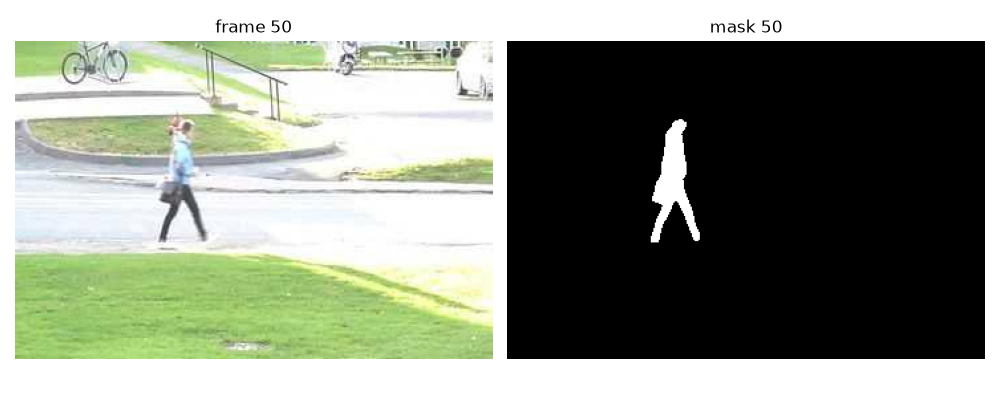

In [3]:
nb_frames = len(os.listdir(FRAMES_dir))
print("frames :", nb_frames)

frame = load_frame(50)
mask = load_mask(50)
imshow([frame, mask * 255], ["frame 50", "mask 50"])

## HSV

rgb2hsv

(<Figure size 1200x300 with 3 Axes>,
 array([[<Axes: title={'center': 'hue'}>,
         <Axes: title={'center': 'saturation'}>,
         <Axes: title={'center': 'value'}>]], dtype=object))

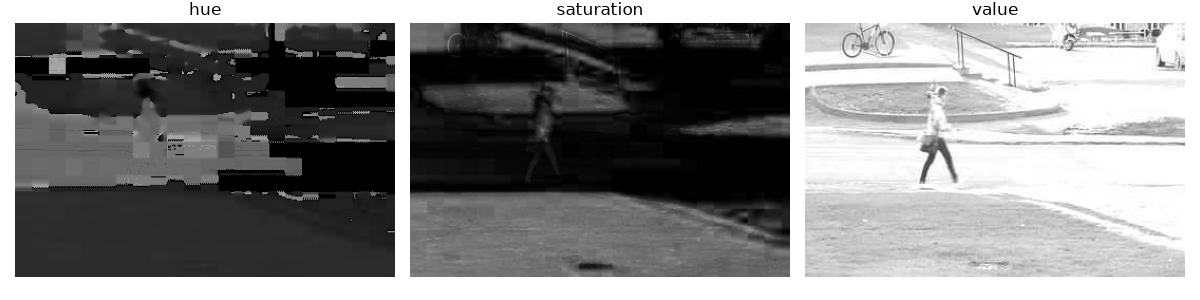

In [4]:
#convert RGB -> HSV
hsv = cv2.cvtColor(frame, cv2.COLOR_RGB2HSV)

#look at the 3 channels
imshow([hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]], ["hue", "saturation", "value"], figsize=(12, 3))

## RECOLOR

In [ ]:
def recolor(frame, mask, hue=None, hue_shift=0, satur_add=0, val_mult=1.0):
    #if hue = None, keep original color
    hsv = cv2.cvtColor(frame, cv2.COLOR_RGB2HSV).astype(np.float32)
    h = hsv[:, :, 0]
    s = hsv[:, :, 1]
    v = hsv[:, :, 2]

    #change only the object pixels : 
    if hue is not None : 
        h[mask] = hue
    h[mask] = (h[mask]+ hue_shift) % 180
    s[mask] = np.clip(s[mask] + satur_add, 0, 255)
    v[mask] = np.clip(v[mask]*val_mult, 0, 255)

    hsv = hsv.astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
